# Google Play Apps 2026: gelir modeli, tür ve kurulum bandı

**Ana soru:** Google Play'de gelir modeli (reklam, uygulama içi satın alma, ücretli, hiçbiri) tür ve kurulum bandına göre nasıl değişiyor?

- Veri: `google_play_apps_2026_sample.csv` (Kaggle `fliarbi/google-play-apps-2026`), tam verinin %9'u, **geliştirici bazlı hash örneklemi** (rastgele uygulama örneği değil).
- ABD mağazası, tarama 7-8 Haziran 2026. Yalnızca Android.
- Lisans: CC BY-NC-SA 4.0 (Kaggle). Ticari kullanım yok, atıf zorunlu, türevler aynı lisansla paylaşılır.
- Notebook baştan sona çalışır: ham CSV → temizleme → SQLite → 10 SQL sorusu → grafikler. Veri `data/` altında olmalı (README'deki indirme komutu).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

## Adım 2: Ham verinin doğrulanması

In [2]:
from validate import load_raw

raw = load_raw()
print(f"{raw.shape[0]:,} satır x {raw.shape[1]} sütun")
pd.DataFrame({
    "dtype": raw.dtypes.astype(str),
    "eksik": raw.isna().sum(),
    "eksik_%": (raw.isna().mean() * 100).round(2),
})

100,013 satır x 19 sütun


,dtype,eksik,eksik_%
app_id,str,0,0.00
title,str,0,0.00
developer,str,0,0.00
developer_domain,str,36486,36.48
genre,str,0,0.00
is_game,bool,0,0.00
installs,str,0,0.00
score,float64,68258,68.25
ratings,float64,68258,68.25
reviews,float64,68258,68.25


In [3]:
print(f"Tam tekrarlı satır: {raw.duplicated().sum():,}, tekrarlı app_id: {raw['app_id'].duplicated().sum():,}")
print(f"score 1-5 dışı: {((raw['score'] < 1) | (raw['score'] > 5)).sum():,}")
print(f"free=False ama price boş: {((~raw['free']) & raw['price'].isna()).sum():,}")
print(f"Sports türünde is_game dağılımı: {raw.loc[raw['genre'] == 'Sports', 'is_game'].value_counts().to_dict()}")

Tam tekrarlı satır: 0, tekrarlı app_id: 0
score 1-5 dışı: 0
free=False ama price boş: 13
Sports türünde is_game dağılımı: {False: 1984, True: 351}


## Adım 3: Temizleme ve türetilmiş sütunlar
Kararlar `DEVLOG.md`'de. Satır silinmez; oyun olan Sports satırları `Sports (Game)` olur.

In [4]:
from clean import CLEAN_CSV, clean

df = clean(raw)
df.to_csv(CLEAN_CSV, index=False)
print(f"{df.shape[0]:,} satır x {df.shape[1]} sütun")
df["monetization"].value_counts().to_frame("n").assign(pct=lambda t: (t["n"] / len(df) * 100).round(2))

100,013 satır x 23 sütun


,n,pct
monetization,,
free_clean,49390,49.38
ads_only,30871,30.87
ads_iap,12483,12.48
iap_only,5793,5.79
paid,1476,1.48


## Adım 4: Örneklem sağlaması
Kıyas değerleri REPORT.md'deki tam veri oranlarıdır, bulgu değildir. Düzeltme yapılmaz.

In [5]:
from sample_check import developer_key, shares, top_developers

shares(df)

,örneklem_%,tam_veri_%,fark_puan
contains_ads,43.44,43.0,0.44
offers_iap,18.50,18.0,0.50
paid,1.48,1.4,0.08


In [6]:
counts = developer_key(df).value_counts()
print(f"Geliştirici: {counts.size:,}, tek uygulamalı: {(counts == 1).mean() * 100:.1f}%")
top_developers(df)

Geliştirici: 47,956, tek uygulamalı: 79.9%


,n_apps,pay_%,kümülatif_%
Individual developer | <no domain>,6022,6.02,6.02
WABiz - Aplicativos para Delivery | <no domain>,534,0.53,6.55
Cool keyboard skin for Android | <no domain>,390,0.39,6.94
"GPSmyCity.com, Inc. | gpsmycity.com",383,0.38,7.32
Delicate theme for Android App | <no domain>,374,0.37,7.69
Fancy keyboard for theme apps | <no domain>,289,0.29,7.98
Education Media | <no domain>,286,0.29,8.27
WABiz - Aplicativos para Delivery | wabiz.com.br,285,0.28,8.55
Branded Apps by MINDBODY | mindbodyonline.com,273,0.27,8.82
ArtsPlanet | artsplanet.biz,266,0.27,9.09


## Adım 5: SQLite'a yükleme (`sql/schema.sql`)

In [7]:
from load_db import load

load()

Yazıldı: apps.db
  developers: 47,956 satır
  genres: 49 satır
  install_bands: 15 satır
  apps: 100,013 satır
  foreign_key_check hatası: 0


## Adım 6: SQL soruları (`sql/queries.sql`)
Minimum örnek kuralı: tür karşılaştırmalarında n < 200 olan türler elenir (Comics 74, Libraries & Demo 127, Music 143).

In [8]:
from queries import parse_queries, run

QUESTIONS = parse_queries()
results = {}

In [9]:
qid = "Q1"
print(qid, QUESTIONS[qid][0])
results[qid] = run(qid)
results[qid]

Q1 Tür başına uygulama sayısı ve toplam içindeki payı nedir?


,genre,is_game,n,pct
0,Education,0,10438,10.44
1,Tools,0,7874,7.87
2,Business,0,5989,5.99
3,Entertainment,0,5106,5.11
4,Music & Audio,0,4749,4.75
5,Finance,0,4747,4.75
6,Productivity,0,4720,4.72
7,Food & Drink,0,4164,4.16
8,Lifestyle,0,4153,4.15
9,Shopping,0,3848,3.85


In [10]:
qid = "Q2"
print(qid, QUESTIONS[qid][0])
results[qid] = run(qid)
results[qid]

Q2 Kurulum bandına göre gelir modeli dağılımı nasıl değişiyor?


,band_rank,installs,n,free_clean_pct,ads_only_pct,ads_iap_pct,iap_only_pct,paid_pct
0,1,"1,000+",37498,64.05,23.81,5.61,4.34,2.20
1,2,"5,000+",13036,54.41,30.63,8.30,5.26,1.40
2,3,"10,000+",22964,45.56,35.72,11.27,6.16,1.29
3,4,"50,000+",6890,37.74,38.75,15.81,6.92,0.78
4,5,"100,000+",10598,31.86,38.42,20.79,8.08,0.85
5,6,"500,000+",2727,24.86,37.66,29.15,7.96,0.37
6,7,"1,000,000+",4065,21.13,34.86,35.10,8.54,0.37
7,8,"5,000,000+",974,14.99,28.13,49.28,7.29,0.31
8,9,"10,000,000+",1017,12.59,23.30,56.05,7.96,0.10
9,10,"50,000,000+",128,12.50,17.19,60.94,9.38,0.00


In [11]:
qid = "Q3"
print(qid, QUESTIONS[qid][0])
results[qid] = run(qid)
results[qid]

Q3 Reklam oranı en yüksek 10 tür hangisi (n >= 200)?


,genre,n,ads_pct,iap_pct
0,Simulation,1662,90.13,48.62
1,Word,385,89.35,52.73
2,Racing,423,88.89,33.57
3,Action,1030,84.27,47.96
4,Puzzle,2331,82.88,47.62
5,Casual,2532,82.50,32.62
6,Personalization,3753,81.24,10.02
7,Trivia,314,81.21,42.04
8,Photography,1298,81.20,23.81
9,Arcade,970,78.25,39.48


In [12]:
qid = "Q4"
print(qid, QUESTIONS[qid][0])
results[qid] = run(qid)
results[qid].head(20)

Q4 Her tür içinde uygulamalar puana göre nasıl sıralanıyor (ratings >= 1000, n >= 200 tür)?


,genre,title,score,ratings,monetization,score_rank,n_in_genre
0,Action,Elastic Master,4.91,7901,ads_iap,1,421
1,Action,Flappy Dragon,4.86,63151,ads_iap,2,421
2,Action,La Libertad Arrasa: Milei,4.86,1396,ads_only,2,421
3,Action,Cars Royale: League of Rocket,4.85,4687,ads_iap,4,421
4,Action,Mr Symbiote Shooting Puzzle,4.83,30911,ads_iap,5,421
5,Action,Tank vs Zombies: Tank Battle,4.81,2930,ads_iap,6,421
6,Action,Dragon Wings - Space Shooter,4.79,81626,ads_iap,7,421
7,Action,Toonsters: Crossing Worlds,4.77,17422,ads_iap,8,421
8,Action,Animal Shooting: Jungle Hunter,4.77,2733,ads_iap,8,421
9,Action,Shadow of Death: Dark Knight,4.75,536898,paid,10,421


In [13]:
qid = "Q5"
print(qid, QUESTIONS[qid][0])
results[qid] = run(qid)
results[qid].head(20)

Q5 Her türün en yüksek puanlı 3 uygulaması hangisi (ratings >= 1000, eşitlikte çok oy alan önde)?


,genre,rn,title,score,ratings,monetization
0,Action,1,Elastic Master,4.91,7901,ads_iap
1,Action,2,Flappy Dragon,4.86,63151,ads_iap
2,Action,3,La Libertad Arrasa: Milei,4.86,1396,ads_only
3,Adventure,1,라이프애프터,5.00,56711,iap_only
4,Adventure,2,Sukhu Dukhu adventure,5.00,1338,ads_only
5,Adventure,3,EscapeGame Snowy Onsen,4.84,1008,ads_only
6,Arcade,1,Jacks Adventure,5.00,1823,ads_only
7,Arcade,2,MiniBattles - 2 to 6 Players,4.81,20471,ads_only
8,Arcade,3,Blocky Snowboarding,4.81,2565,ads_iap
9,Art & Design,1,Stylish Name Art Maker,4.93,15269,ads_iap


In [14]:
qid = "Q6"
print(qid, QUESTIONS[qid][0])
results[qid] = run(qid)
results[qid]

Q6 En çok uygulaması olan 10 geliştirici kim ve toplam içindeki payı ne?


,developer,developer_domain,is_generic,n_apps,pct
0,WABiz - Aplicativos para Delivery,NaN,0,534,0.53
1,Cool keyboard skin for Android,NaN,0,390,0.39
2,"GPSmyCity.com, Inc.",gpsmycity.com,0,383,0.38
3,Delicate theme for Android App,NaN,0,374,0.37
4,Fancy keyboard for theme apps,NaN,0,289,0.29
5,Education Media,NaN,0,286,0.29
6,WABiz - Aplicativos para Delivery,wabiz.com.br,0,285,0.28
7,Branded Apps by MINDBODY,mindbodyonline.com,0,273,0.27
8,ArtsPlanet,artsplanet.biz,0,266,0.27
9,NUPUIT,nupuit.com,0,252,0.25


In [15]:
qid = "Q7"
print(qid, QUESTIONS[qid][0])
results[qid] = run(qid)
results[qid]

Q7 Yayın yılı kohortuna göre ücretsiz / reklam / IAP oranı nasıl değişiyor?


,release_year,n,free_pct,ads_pct,iap_pct
0,2010,220,85.91,46.36,18.64
1,2011,627,90.43,54.23,17.38
2,2012,895,91.62,43.58,19.89
3,2013,2067,96.95,65.31,43.35
4,2014,1947,96.66,52.34,21.31
5,2015,2685,97.36,52.85,19.44
6,2016,3275,97.74,46.84,20.64
7,2017,4549,98.20,51.37,18.66
8,2018,5626,98.67,51.74,16.32
9,2019,6404,98.61,49.25,15.60


In [16]:
qid = "Q8"
print(qid, QUESTIONS[qid][0])
results[qid] = run(qid)
results[qid]

Q8 Türler büyükten küçüğe dizildiğinde kümülatif pay nedir, ilk 10 tür uygulamaların % kaçı?


,genre_rank,genre,n,pct,cumulative_pct
0,1,Education,10438,10.44,10.44
1,2,Tools,7874,7.87,18.31
2,3,Business,5989,5.99,24.30
3,4,Entertainment,5106,5.11,29.40
4,5,Music & Audio,4749,4.75,34.15
5,6,Finance,4747,4.75,38.90
6,7,Productivity,4720,4.72,43.62
7,8,Food & Drink,4164,4.16,47.78
8,9,Lifestyle,4153,4.15,51.93
9,10,Shopping,3848,3.85,55.78


In [17]:
qid = "Q9"
print(qid, QUESTIONS[qid][0])
results[qid] = run(qid)
results[qid]

Q9 Son 12 ayda (tarama tarihi 2026-06-08'e göre > 365 gün) güncellenmemiş uygulama oranı kurulum bandına göre nasıl?


,band_rank,installs,n,n_stale,stale_pct,mean_days_since_update
0,1,"1,000+",37498,12130,32.35,418
1,2,"5,000+",13036,3899,29.91,413
2,3,"10,000+",22964,6358,27.69,395
3,4,"50,000+",6890,1699,24.66,376
4,5,"100,000+",10598,2320,21.89,351
5,6,"500,000+",2727,488,17.90,328
6,7,"1,000,000+",4065,646,15.89,290
7,8,"5,000,000+",974,140,14.37,248
8,9,"10,000,000+",1017,111,10.91,180
9,10,"50,000,000+",128,13,10.16,134


In [18]:
qid = "Q10"
print(qid, QUESTIONS[qid][0])
results[qid] = run(qid)
results[qid]

Q10 Productivity, Finance ve Entertainment türlerinin gelir modeli profili tüm veriyle nasıl kıyaslanıyor?


,segment,n,free_clean_pct,ads_only_pct,ads_iap_pct,iap_only_pct,paid_pct
0,Entertainment,5106,34.57,47.98,10.56,6.52,0.37
1,Finance,4747,80.16,13.69,3.50,2.38,0.27
2,Productivity,4720,64.32,18.09,9.15,7.61,0.83
3,ALL,100013,49.38,30.87,12.48,5.79,1.48


## Adım 7: Grafikler (`figures/`)
Her grafikte başlık, eksen adı ve birim, her çubukta n, altta tek cümlelik okuma notu var. 50M ve üstü kurulum bantları (toplam n=244) küçük n nedeniyle birleştirildi. 05'te bantlar 3 büyüklük grubunda toplandı (<100K, 100K-1M, 1M+). Gelir modeli renkleri tüm grafiklerde sabit.

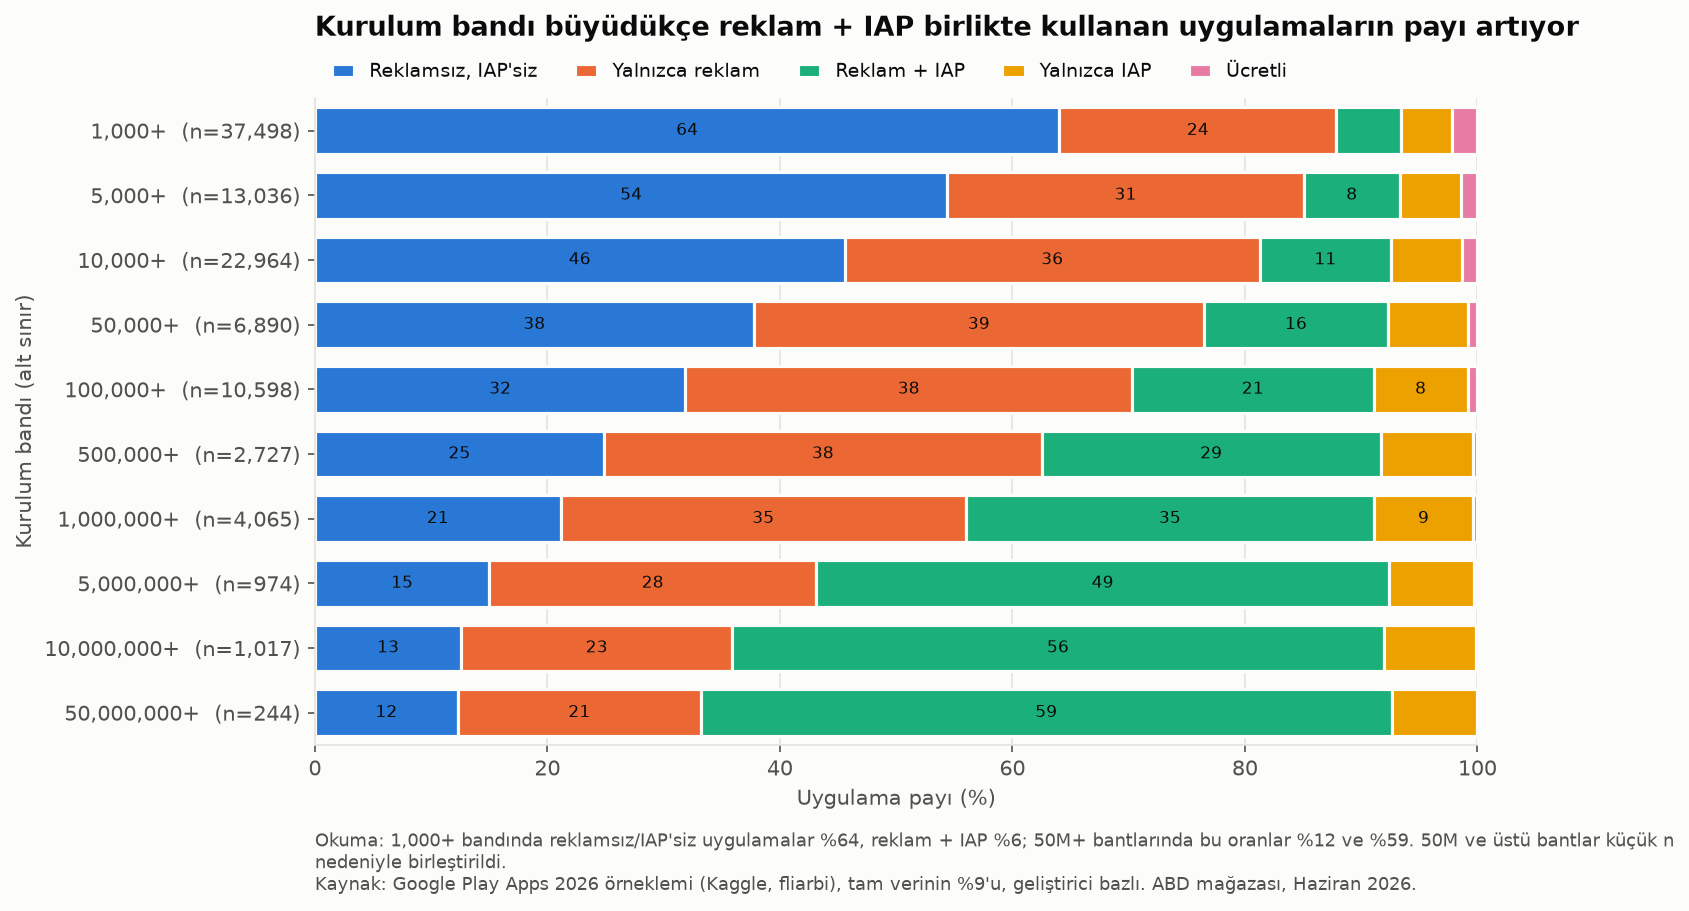

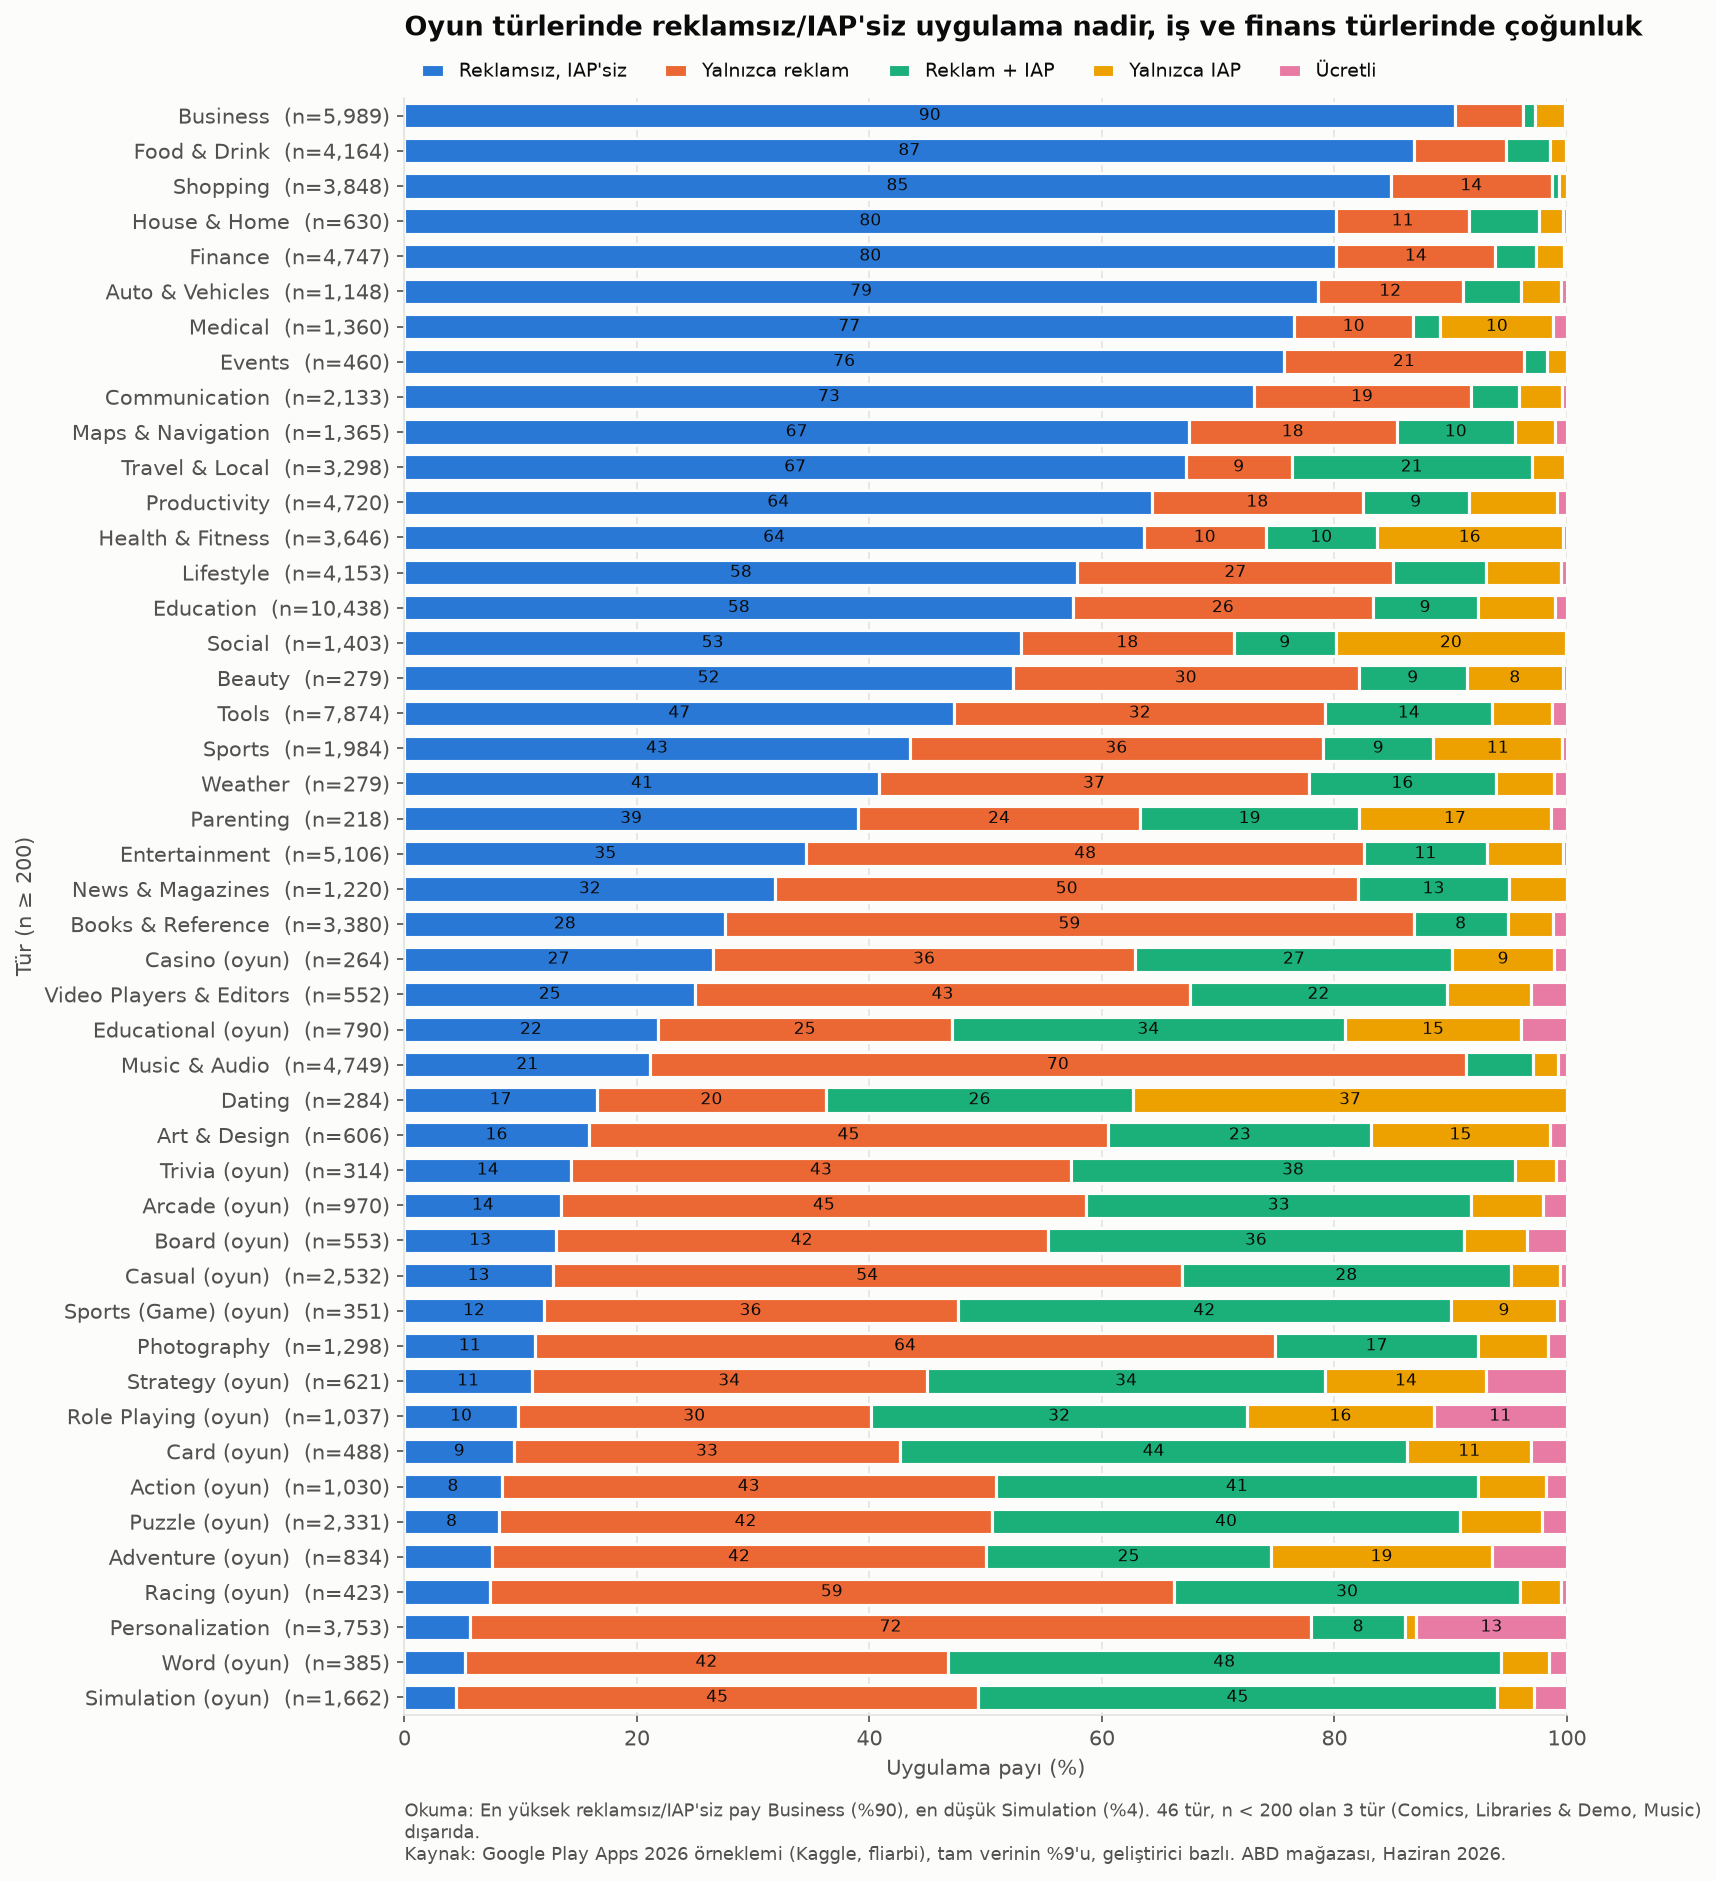

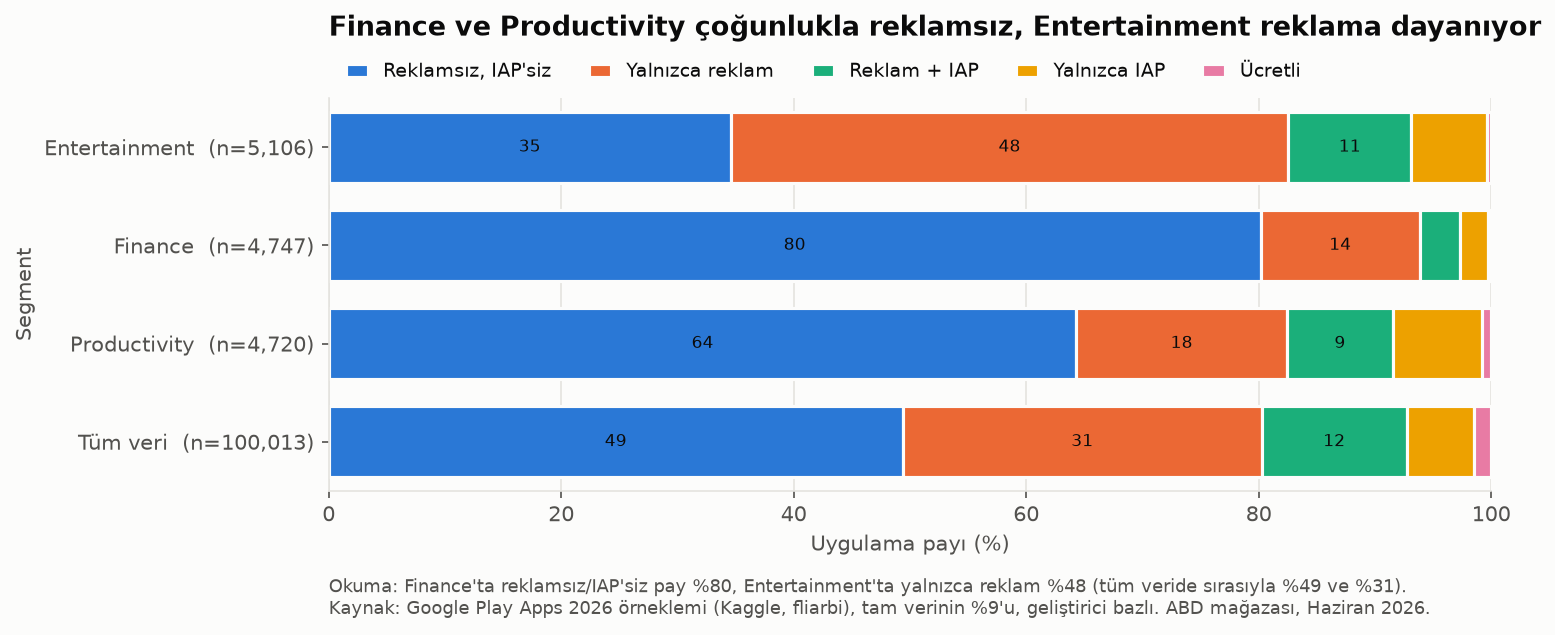

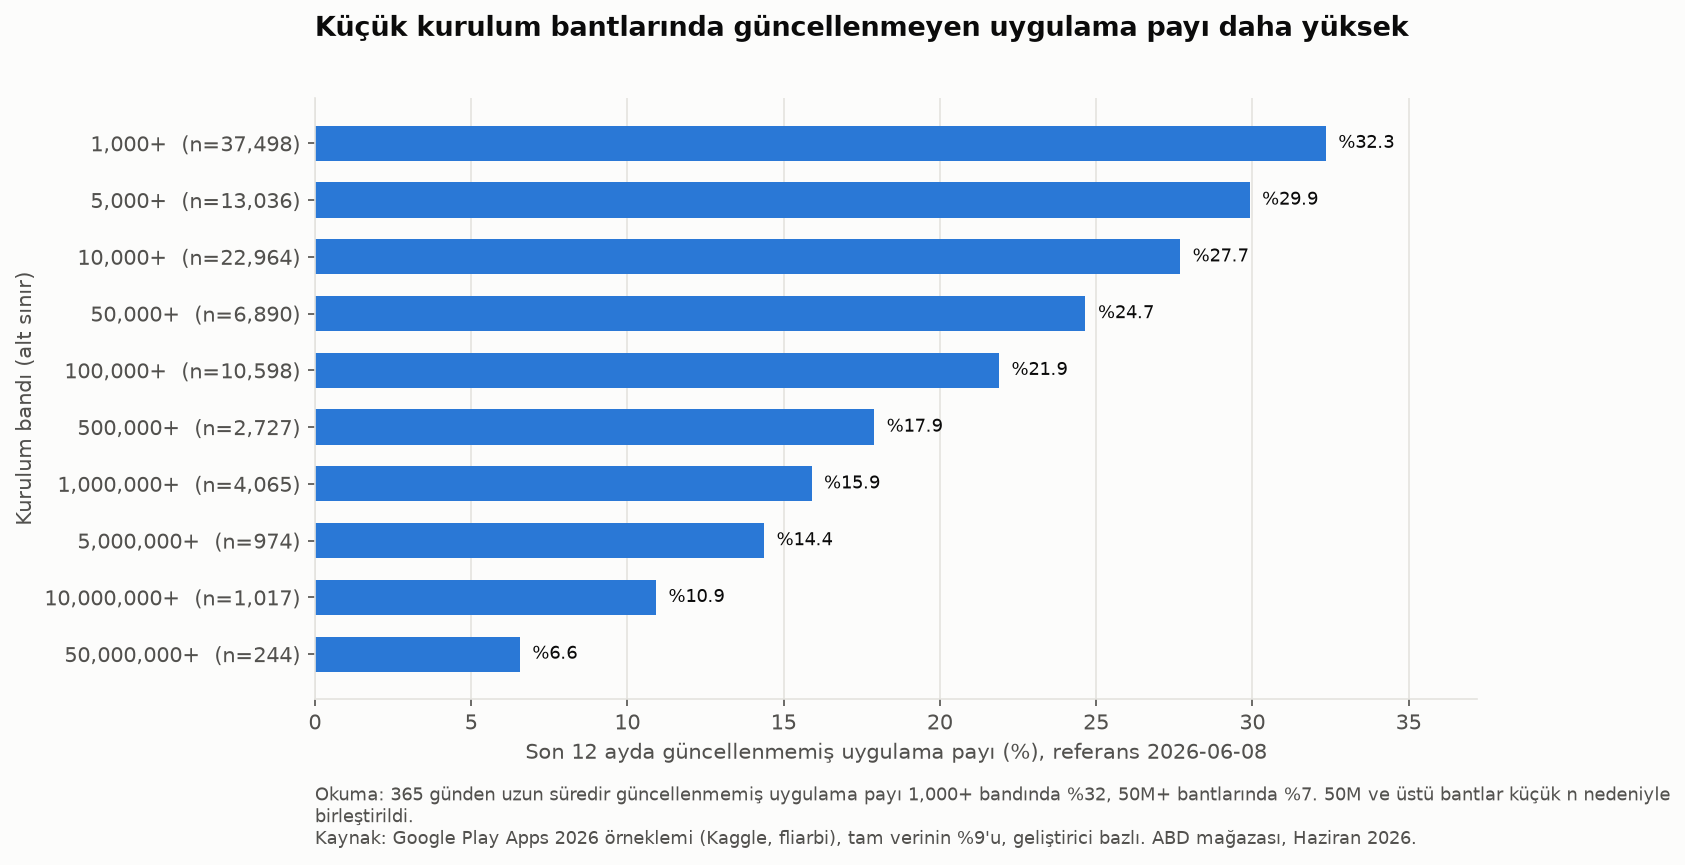

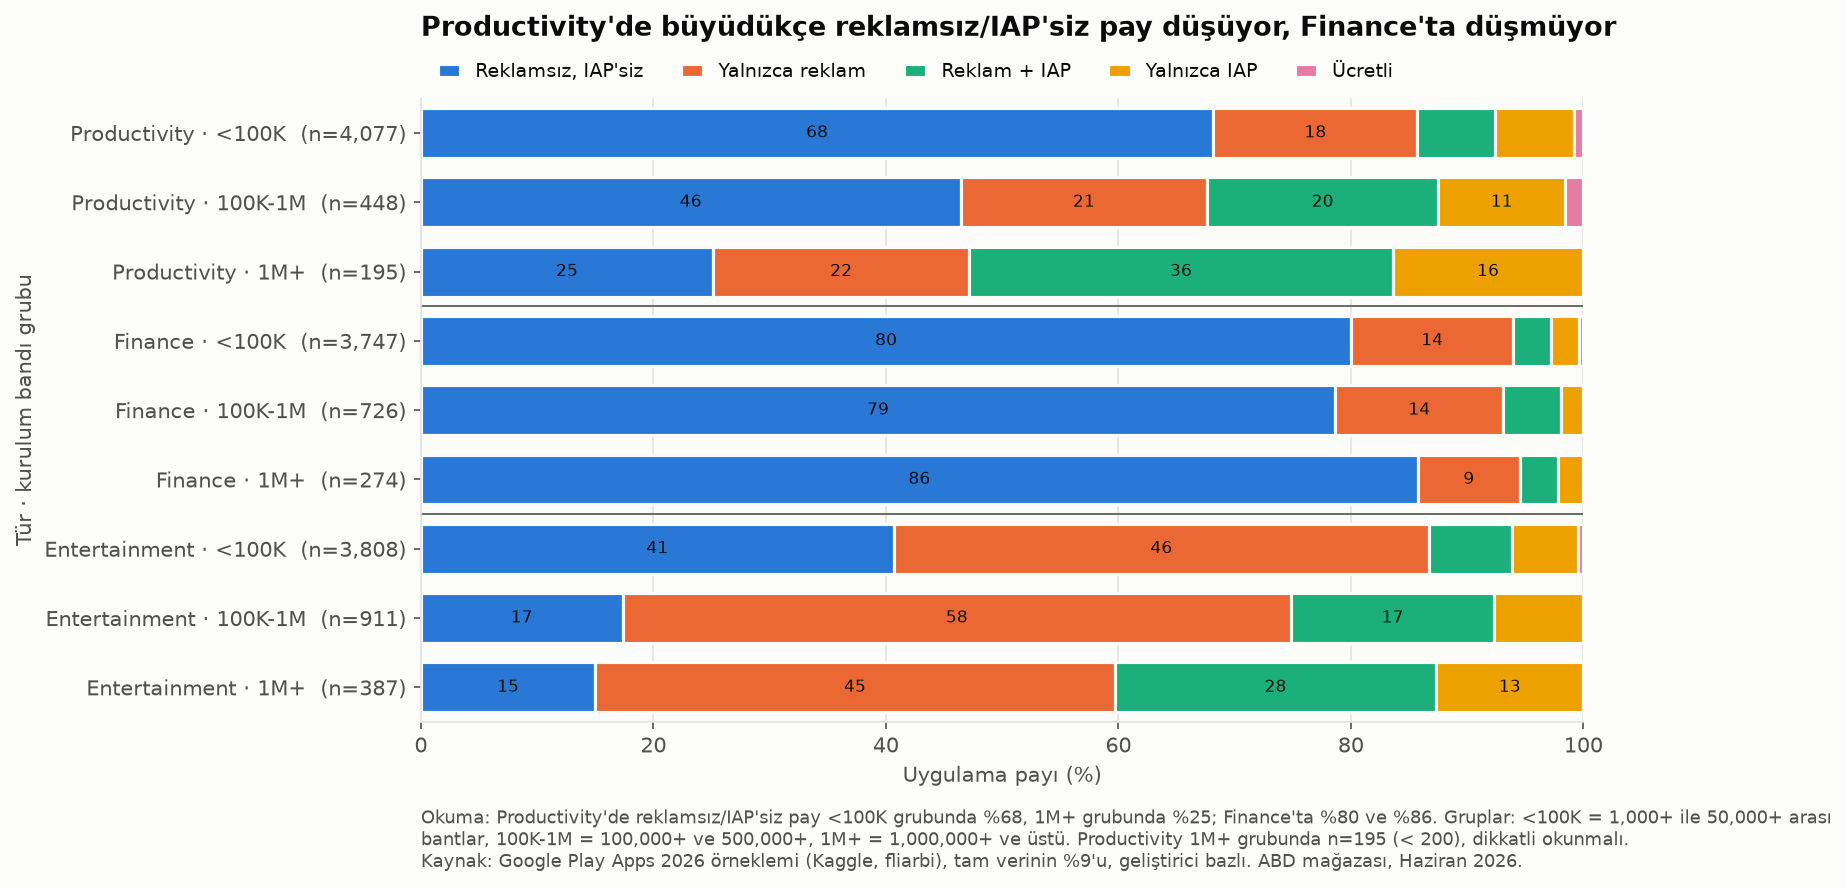

In [19]:
from IPython.display import Image, display
import figures

figures.FIG_DIR.mkdir(exist_ok=True)
fig_tables = {
    "01_band_monetization": figures.fig_band_monetization(),
    "02_genre_monetization": figures.fig_genre_monetization(),
    "03_focus_genres": figures.fig_focus_genres(results["Q10"]),
    "04_stale_by_band": figures.fig_stale_by_band(),
    "05_focus_genres_by_size": figures.fig_focus_by_size(),
}
for name in fig_tables:
    display(Image(filename=str(figures.FIG_DIR / f"{name}.png"), width=900))

## Adım 8: Dashboard özet tablosu (`app/summary/`)
Dashboard ham satır okumaz. Geliştirici × tür × kurulum bandı × gelir modeli kırılımında uygulama sayısı içeren özet tablo üretilir. Uygulama adı ve `app_id` yok; örneklemde 20'den az uygulaması olan geliştiricilerin adı numarayla gizlenir.

In [20]:
from build_summaries import SUMMARY, build

summary = build()
summary.to_csv(SUMMARY, index=False)
assert summary["n"].sum() == len(df), "özet tablo tüm uygulamaları kapsamalı"
print(f"{len(summary):,} satır, n toplamı {summary['n'].sum():,}, adı görünen geliştirici {summary.loc[summary['named'] == 1, 'dev_no'].nunique()}")
summary.head()

69,841 satır, n toplamı 100,013, adı görünen geliştirici 389


,dev_no,developer_label,named,is_generic,genre,is_game,installs,band_rank,monetization,n
0,1,Individual developer (domain yok),1,1,Action,1,"1,000+",1,ads_iap,3
1,1,Individual developer (domain yok),1,1,Action,1,"1,000+",1,ads_only,5
2,1,Individual developer (domain yok),1,1,Action,1,"1,000+",1,free_clean,2
3,1,Individual developer (domain yok),1,1,Action,1,"1,000+",1,paid,1
4,1,Individual developer (domain yok),1,1,Action,1,"5,000+",2,ads_iap,2
